# Pull Request Complexity Analysis

This notebook creates a **0–100 PR complexity score** for each pull request.

The score is designed to measure the *realized complexity* of a PR using:

- **30% Technical size** — code lines modified
- **20% File breadth** — files touched
- **25% Review burden** — review comments and reviewers
- **10% Configuration impact** — configuration lines modified
- **15% Semantic breadth** — number of detected PR categories

## 1. Imports

In order to run this code use the cleaned dataset ".csv" file. Store this file in the data subdirectory on the local machine. This file has the cleaned version of the title and body as well as the keyword matched categories. The cleaned dataset can be downloaded from OneDrive.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 2. Select the dataframe

This preserves your original dataframe and creates a working copy.


In [3]:
df_title_body = pd.read_csv("../data/microsoft/df_title_body_with_categories.csv")
df = df_title_body

print(df_title_body.shape)
df_title_body.head()

print("Rows:", df_title_body.shape[0])
print("Columns:", df_title_body.shape[1])
print("Shape:", df_title_body.shape)

(556433, 53)
Rows: 556433
Columns: 53
Shape: (556433, 53)


In [4]:
pd.set_option("display.max_columns", None)
df_title_body.head(10)

,customer_id,user_id,repository_id,pull_request_id,oid,title,body,combined_text_nlp,merge_day,merge_month,had_copilot_seat,files_added,files_deleted,files_modified,files_touched,lines_modified,code_lines_modified,config_lines_modified,minutes_to_merge,num_reviewers,num_review_comments,is_code_pr,standardized_complexity_score,complexity_score,lines_added_by_language,lines_deleted_by_language,languages_list,title_clean,body_clean,title_lower,body_lower,detected_language,title_clean_nlp,body_clean_nlp,title_word_count,body_word_count,has_title,has_body,short_body,kw_feature,kw_bug_fix,kw_refactor,kw_documentation,kw_testing,kw_dependency,kw_security,kw_performance,kw_configuration,kw_release,kw_revert,keyword_categories,keyword_category_count,has_keyword_match
0,13213,77245923,498431566,3140092528,f26bb5924a261dccab7dc82e7f6301abcd362ecb,Added new branch policy for watchdog test as s...,NaN,policy watchdog specified ymlfiles protection ...,2026-01-01,2026-01-01,False,1,0,1,2,9,0,9,0,0,0,False,-43.14,31.00,"{'YAML': 9.0, 'C#': None, 'Smalltalk': None, '...","{'YAML': None, 'Smalltalk': None, 'C#': None, ...",['YAML'],Added new branch policy for watchdog test as s...,NaN,added new branch policy for watchdog test as s...,NaN,en,policy watchdog specified ymlfiles protection ...,NaN,16,0,True,False,True,False,False,False,False,True,False,False,False,False,False,False,['testing'],1,True
1,13213,77245923,498431566,3140093862,c1dfdedcd6b74167962e9a8fab618f45f5705fd5,Added new branch policy for watchdog test as s...,NaN,policy watchdog specified ymlfiles protection ...,2026-01-01,2026-01-01,False,1,0,1,2,9,0,9,0,0,0,False,-43.14,31.00,"{'YAML': 9.0, 'C#': None, 'Smalltalk': None, '...","{'YAML': None, 'Smalltalk': None, 'C#': None, ...",['YAML'],Added new branch policy for watchdog test as s...,NaN,added new branch policy for watchdog test as s...,NaN,en,policy watchdog specified ymlfiles protection ...,NaN,16,0,True,False,True,False,False,False,False,True,False,False,False,False,False,False,['testing'],1,True
2,13213,77245923,498431566,3140095136,d337e87e97a1394077cc81be9749414fc8c85a4c,Added new branch policy for watchdog test as s...,NaN,policy watchdog specified ymlfiles protection ...,2026-01-01,2026-01-01,False,1,0,1,2,11,0,11,0,0,0,False,-43.11,32.00,"{'YAML': 11.0, 'C#': None, 'Smalltalk': None, ...","{'YAML': None, 'Smalltalk': None, 'C#': None, ...",['YAML'],Added new branch policy for watchdog test as s...,NaN,added new branch policy for watchdog test as s...,NaN,en,policy watchdog specified ymlfiles protection ...,NaN,18,0,True,False,True,False,False,False,False,True,False,False,False,False,False,False,['testing'],1,True
3,13213,77245923,498431566,3140096196,7d253b36f45b4d88c6b86f6c27128a9132fbb56b,Added new branch policy for watchdog test as s...,NaN,policy watchdog specified ymlfiles protection ...,2026-01-01,2026-01-01,False,1,0,1,2,11,0,11,0,0,0,False,-43.11,32.00,"{'YAML': 11.0, 'C#': None, 'Smalltalk': None, ...","{'YAML': None, 'Smalltalk': None, 'C#': None, ...",['YAML'],Added new branch policy for watchdog test as s...,NaN,added new branch policy for watchdog test as s...,NaN,en,policy watchdog specified ymlfiles protection ...,NaN,18,0,True,False,True,False,False,False,False,True,False,False,False,False,False,False,['testing'],1,True
4,13213,77245923,498431566,3140097164,61a41944c2b478da6380cef0c47216661ecb9a1f,Added new branch policy for watchdog test as s...,NaN,policy watchdog specified ymlfiles protection ...,2026-01-01,2026-01-01,False,1,0,1,2,11,0,11,0,0,0,False,-43.11,32.00,"{'YAML': 11.0, 'C#': None, 'Smalltalk': None, ...","{'YAML': None, 'Smalltalk': None, 'C#': None, ...",['YAML'],Added new branch policy for watchdog test as s...,NaN,added new branch policy for watchdog test as s...,NaN,en,policy watchdog specified ymlfiles protection ...,NaN,18,0,True,False,True,False,False,False,False,True,False,False,False,False,False,False,['testing'],1,True
5,13213,77245923,498431566,3140249862,17b8e1eccd59b9b943a729b

## 3. Calculate PR Complexity

The code below:

1. Safely reads each complexity variable.
2. Uses `log1p()` to reduce the effect of extremely large PR outliers.
3. Converts each component to a percentile from 0–1.
4. Combines the components into one 0–100 score.
5. Assigns each PR to a complexity level.


In [5]:
# ============================================================
# PR COMPLEXITY SCORE
# ============================================================

def get_numeric_column(df, column, fallback=None):
    """Return a clean non-negative numeric Series."""
    if column in df.columns:
        values = pd.to_numeric(df[column], errors="coerce").fillna(0)
    elif fallback is not None and fallback in df.columns:
        values = pd.to_numeric(df[fallback], errors="coerce").fillna(0)
    else:
        values = pd.Series(0, index=df.index, dtype=float)

    return values.clip(lower=0)


def percentile_score(series):
    """
    Reduce skew with log1p, then convert values to percentile ranks.
    Returns values approximately between 0 and 1.
    """
    return np.log1p(series).rank(pct=True, method="average")


# ------------------------------------------------------------
# 1. TECHNICAL SIZE
# Prefer actual code lines; fall back to all modified lines.
# ------------------------------------------------------------
code_change = get_numeric_column(
    df,
    "code_lines_modified",
    fallback="lines_modified"
)


# ------------------------------------------------------------
# 2. FILE BREADTH
# ------------------------------------------------------------
if "files_touched" in df.columns:
    files_touched = get_numeric_column(df, "files_touched")
else:
    files_added = get_numeric_column(df, "files_added")
    files_deleted = get_numeric_column(df, "files_deleted")
    files_modified = get_numeric_column(df, "files_modified")

    files_touched = files_added + files_deleted + files_modified


# ------------------------------------------------------------
# 3. REVIEW BURDEN
# ------------------------------------------------------------
review_comments = get_numeric_column(df, "num_review_comments")
reviewers = get_numeric_column(df, "num_reviewers")


# ------------------------------------------------------------
# 4. CONFIGURATION IMPACT
# ------------------------------------------------------------
config_change = get_numeric_column(df, "config_lines_modified")


# ------------------------------------------------------------
# 5. SEMANTIC / CATEGORY BREADTH
# If unavailable, this component contributes 0.
# ------------------------------------------------------------
category_count = get_numeric_column(df, "keyword_category_count")


# ------------------------------------------------------------
# Convert each variable to a percentile score.
# ------------------------------------------------------------
df["complexity_code_size"] = percentile_score(code_change)
df["complexity_file_breadth"] = percentile_score(files_touched)
df["complexity_review_comments"] = percentile_score(review_comments)
df["complexity_reviewers"] = percentile_score(reviewers)
df["complexity_config"] = percentile_score(config_change)
df["complexity_category_breadth"] = percentile_score(category_count)


# ------------------------------------------------------------
# Review burden:
# comments receive more weight than reviewer count.
# ------------------------------------------------------------
df["complexity_review_burden"] = (
    0.60 * df["complexity_review_comments"]
    + 0.40 * df["complexity_reviewers"]
)


# ------------------------------------------------------------
# FINAL SCORE: 0–100
# ------------------------------------------------------------
df["pr_complexity_score"] = 100 * (
    0.30 * df["complexity_code_size"]
    + 0.20 * df["complexity_file_breadth"]
    + 0.25 * df["complexity_review_burden"]
    + 0.10 * df["complexity_config"]
    + 0.15 * df["complexity_category_breadth"]
)

df["pr_complexity_score"] = df["pr_complexity_score"].round(2)


# ------------------------------------------------------------
# Complexity levels based on score quartiles.
# ------------------------------------------------------------
df["pr_complexity_level"] = pd.qcut(
    df["pr_complexity_score"],
    q=[0, 0.25, 0.50, 0.75, 1.0],
    labels=["Low", "Moderate", "High", "Very High"],
    duplicates="drop"
)

print("Complexity calculation complete.")


Complexity calculation complete.


## 4. Inspect the Results

This shows the complexity distribution and the highest-scoring PRs.


In [6]:
print("PR COMPLEXITY DISTRIBUTION")
display(
    df["pr_complexity_level"]
    .value_counts()
    .sort_index()
    .to_frame("PR_count")
)

print("\nCOMPLEXITY SCORE SUMMARY")
display(df["pr_complexity_score"].describe().to_frame())


PR COMPLEXITY DISTRIBUTION


,PR_count
pr_complexity_level,
Low,139284
Moderate,139004
High,139083
Very High,139062



COMPLEXITY SCORE SUMMARY


,pr_complexity_score
count,"556,433.00"
mean,50.00
std,17.31
min,18.71
25%,35.95
50%,48.04
75%,62.87
max,99.44


In [7]:
display_columns = [

    col for col in [

        "pull_request_id",

        "category",

        "repo_primary_language",

        "code_lines_modified",

        "lines_modified",

        "files_touched",

        "config_lines_modified",

        "num_reviewers",

        "num_review_comments",

        "keyword_category_count",

        "pr_complexity_score",

        "pr_complexity_level",

        "minutes_to_merge"

    ]

    if col in df.columns

]



display(

    df[display_columns]

    .nlargest(20, "pr_complexity_score")

)


,pull_request_id,code_lines_modified,lines_modified,files_touched,config_lines_modified,num_reviewers,num_review_comments,keyword_category_count,pr_complexity_score,pr_complexity_level,minutes_to_merge
335419,3720647863,15226,17123,482,1897,6,318,10,99.44,Very High,42820
232344,3630919944,16230,18237,316,2007,6,82,8,99.21,Very High,12021
298626,3621922343,7721,19078,275,11357,5,80,8,99.09,Very High,46752
209074,3591738965,12991,16720,228,3729,5,47,8,99.04,Very High,10461
151599,3523769730,18729,19584,597,855,5,58,9,98.96,Very High,138
157859,3529233845,6705,17367,550,10662,4,113,8,98.89,Very High,575
259968,3668746340,13313,16388,257,3075,5,73,7,98.84,Very High,14544
449487,4138947160,12750,17479,187,4729,5,20,9,98.79,Very High,1215
540449,4309866069,9454,12738,232,3284,6,56,7,98.78,Very High,8354
56942,3176355535,16272,17874,111,1602,5,162,8,98.75,Very High,58928


## 5. Plot the Complexity Distribution


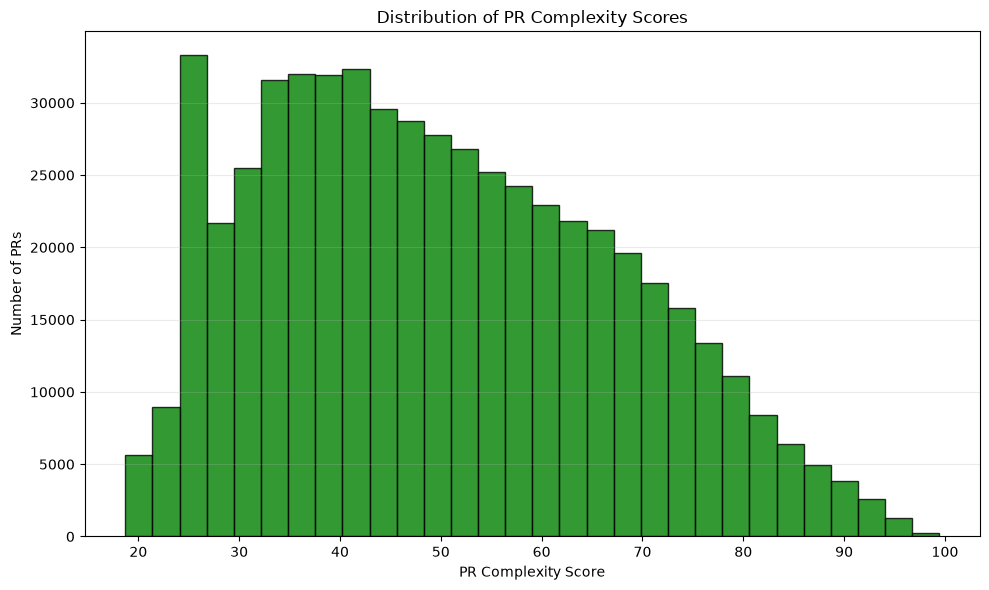

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(df["pr_complexity_score"].dropna(), bins=30, edgecolor="black", color="green", alpha=0.8)

ax.set_title("Distribution of PR Complexity Scores")
ax.set_xlabel("PR Complexity Score")
ax.set_ylabel("Number of PRs")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


## 6. Validate Complexity Against Time to Merge

Merge time is **not part of the complexity score**.

Instead, this section checks whether PRs with higher complexity tend to take longer to merge.


In [9]:
if "minutes_to_merge" in df.columns:
    validation_df = df[
        ["pr_complexity_score", "minutes_to_merge"]
    ].dropna().copy()

    validation_df["hours_to_merge"] = (
        validation_df["minutes_to_merge"] / 60
    )

    pearson_corr = validation_df[
        ["pr_complexity_score", "hours_to_merge"]
    ].corr(method="pearson").iloc[0, 1]

    spearman_corr = validation_df[
        ["pr_complexity_score", "hours_to_merge"]
    ].corr(method="spearman").iloc[0, 1]

    print(f"Pearson correlation:  {pearson_corr:.3f}")
    print(f"Spearman correlation: {spearman_corr:.3f}")
else:
    print("minutes_to_merge is not available.")


Pearson correlation:  0.085
Spearman correlation: 0.398


CORRELATION RESULTS
---------------------------
Pearson - raw merge time: 0.085
Pearson - log merge time: 0.335
Spearman:                 0.398


,complexity_decile,median_complexity,median_hours_to_merge,mean_hours_to_merge,pr_count
0,1,25.88,0.00,7.85,55689
1,2,30.98,0.23,26.32,55731
2,3,35.95,0.45,39.54,55510
3,4,40.58,0.50,28.83,55696
4,5,45.43,0.67,25.53,55662
5,6,50.73,0.88,25.87,55639
6,7,56.47,1.27,31.12,55581
7,8,62.87,1.80,34.66,55666
8,9,70.15,3.12,44.13,55620
9,10,80.59,16.82,73.59,55639


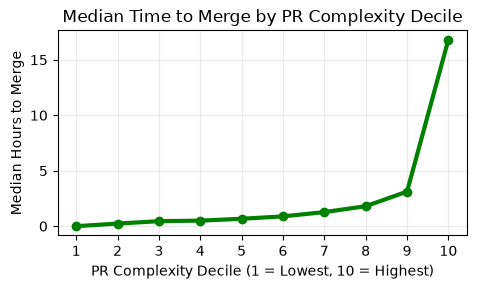

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# BETTER VALIDATION OF PR COMPLEXITY
# ============================================================

validation = df[
    ["pr_complexity_score", "minutes_to_merge"]
].dropna().copy()

# Remove impossible/negative values
validation = validation[
    validation["minutes_to_merge"] >= 0
].copy()

validation["hours_to_merge"] = (
    validation["minutes_to_merge"] / 60
)

# Log transform because merge time is highly skewed
validation["log_hours_to_merge"] = np.log1p(
    validation["hours_to_merge"]
)


# ------------------------------------------------------------
# 1. Compare correlations
# ------------------------------------------------------------

pearson_raw = validation[
    ["pr_complexity_score", "hours_to_merge"]
].corr(method="pearson").iloc[0, 1]

pearson_log = validation[
    ["pr_complexity_score", "log_hours_to_merge"]
].corr(method="pearson").iloc[0, 1]

spearman = validation[
    ["pr_complexity_score", "hours_to_merge"]
].corr(method="spearman").iloc[0, 1]


print("CORRELATION RESULTS")
print("---------------------------")
print(f"Pearson - raw merge time: {pearson_raw:.3f}")
print(f"Pearson - log merge time: {pearson_log:.3f}")
print(f"Spearman:                 {spearman:.3f}")


# ------------------------------------------------------------
# 2. Put complexity into 10 groups
# ------------------------------------------------------------

validation["complexity_decile"] = pd.qcut(
    validation["pr_complexity_score"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1


complexity_summary = (
    validation
    .groupby("complexity_decile")
    .agg(
        median_complexity=("pr_complexity_score", "median"),
        median_hours_to_merge=("hours_to_merge", "median"),
        mean_hours_to_merge=("hours_to_merge", "mean"),
        pr_count=("hours_to_merge", "size")
    )
    .reset_index()
)

display(complexity_summary)


# ------------------------------------------------------------
# 3. Plot median merge time by complexity decile
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(5, 3))

ax.plot(
    complexity_summary["complexity_decile"],
    complexity_summary["median_hours_to_merge"],
    marker="o",
    linewidth=3,
    color="green",
)

ax.set_title("Median Time to Merge by PR Complexity Decile")
ax.set_xlabel("PR Complexity Decile (1 = Lowest, 10 = Highest)")
ax.set_ylabel("Median Hours to Merge")
ax.set_xticks(range(1, 11))
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [11]:
if "minutes_to_merge" in df.columns:
    complexity_merge_summary = (
        df.assign(hours_to_merge=df["minutes_to_merge"] / 60)
        .groupby("pr_complexity_level", observed=True)
        .agg(
            median_complexity=("pr_complexity_score", "median"),
            median_hours_to_merge=("hours_to_merge", "median"),
            mean_hours_to_merge=("hours_to_merge", "mean"),
            pr_count=("pr_complexity_score", "size")
        )
        .reset_index()
    )

    display(complexity_merge_summary)


,pr_complexity_level,median_complexity,median_hours_to_merge,mean_hours_to_merge,pr_count
0,Low,29.49,0.10,21.06,139284
1,Moderate,41.70,0.58,30.16,139004
2,High,54.96,1.15,29.48,139083
3,Very High,72.30,5.63,54.28,139062


## 7. Median Merge Time by Complexity Level

If the complexity score is useful, you would generally expect higher-complexity groups to have greater median merge times, although the relationship does not need to be perfectly linear.


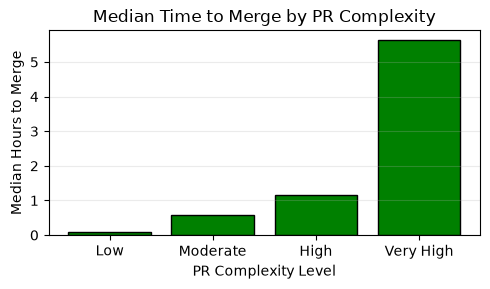

In [12]:
if "minutes_to_merge" in df.columns:
    plot_data = (
        df.assign(hours_to_merge=df["minutes_to_merge"] / 60)
        .groupby("pr_complexity_level", observed=True)["hours_to_merge"]
        .median()
    )

    fig, ax = plt.subplots(figsize=(5, 3))

    ax.bar(
        plot_data.index.astype(str),
        plot_data.values,
        edgecolor="black",
        alpha=1,
        color="green"
    )

    ax.set_title("Median Time to Merge by PR Complexity")
    ax.set_xlabel("PR Complexity Level")
    ax.set_ylabel("Median Hours to Merge")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()


## 8. Complexity by PR Category

Use category as an **analysis variable**, not as an input into the score.

This answers: *Which types of PRs tend to be more complex?*


In [13]:
if "keyword_categories" in df.columns:
    category_complexity = (
        df.groupby("keyword_categories", observed=True)
        .agg(
            median_complexity=("pr_complexity_score", "median"),
            mean_complexity=("pr_complexity_score", "mean"),
            pr_count=("pr_complexity_score", "size")
        )
        .sort_values("median_complexity", ascending=False)
        .reset_index()
    )

    display(category_complexity)
else:
    print("keyword_categories column not found.")


,keyword_categories,median_complexity,mean_complexity,pr_count
0,"['feature', 'refactor', 'testing', 'dependency...",94.62,83.66,3
1,"['security', 'performance', 'configuration', '...",94.57,94.57,1
2,"['bug_fix', 'refactor', 'testing', 'security',...",93.11,93.11,1
3,"['documentation', 'testing', 'performance', 'c...",92.69,92.69,2
4,"['refactor', 'documentation', 'dependency', 's...",92.13,92.13,1
...,...,...,...,...
1845,"['bug_fix', 'documentation', 'dependency', 'se...",32.85,32.85,1
1846,['dependency'],32.46,36.79,5437
1847,"['refactor', 'documentation', 'configuration',...",31.27,31.27,1
1848,"['feature', 'performance', 'release', 'revert']",29.59,29.59,1


## 9. Complexity by Programming Language

This answers: *Do PRs in some languages tend to have greater realized complexity than others?*


In [14]:
language_col = None

for candidate in [
    "languages_list",
]:
    if candidate in df.columns:
        language_col = candidate
        break

if language_col is not None:
    language_complexity = (
        df.groupby(language_col, observed=True)
        .agg(
            median_complexity=("pr_complexity_score", "median"),
            mean_complexity=("pr_complexity_score", "mean"),
            pr_count=("pr_complexity_score", "size")
        )
        .query("pr_count >= 100")
        .sort_values("median_complexity", ascending=False)
        .reset_index()
    )

    display(language_complexity.head(20))
else:
    print("No language column found.")


,languages_list,median_complexity,mean_complexity,pr_count
0,['CSS' 'JSON' 'Markdown' 'TSX' 'TypeScript' 'Y...,85.22,82.99,134
1,['Gradle Kotlin DSL' 'Kotlin' 'Markdown'],81.88,80.41,140
2,['JSON' 'Markdown' 'Python' 'TOML' 'YAML'],79.66,79.16,172
3,['C#' 'JSON' 'Markdown' 'TSX' 'TypeScript'],79.06,78.20,203
4,['JSON' 'Markdown' 'TSX' 'TypeScript' 'YAML'],78.90,77.89,228
5,['Go' 'Markdown' 'Starlark'],78.56,76.55,103
6,['Gradle Kotlin DSL' 'Kotlin' 'XML'],78.13,76.28,218
7,['Kotlin' 'Markdown'],76.28,74.35,389
8,['JSON' 'Markdown' 'PowerShell' 'Python' 'Shell'],75.95,74.62,102
9,['JSON' 'Markdown' 'Python' 'Shell' 'YAML'],75.66,76.61,112


## 10. Save the Complexity Dataset

This saves the original PR data plus the newly calculated complexity components and final score.


In [15]:
OUTPUT_PATH = "../data/microsoft/prs_with_complexity.csv"

df.to_csv(OUTPUT_PATH, index=False)

print(f"Saved {len(df):,} rows to:")
print(OUTPUT_PATH)


Saved 556,433 rows to:
../data/microsoft/prs_with_complexity.csv


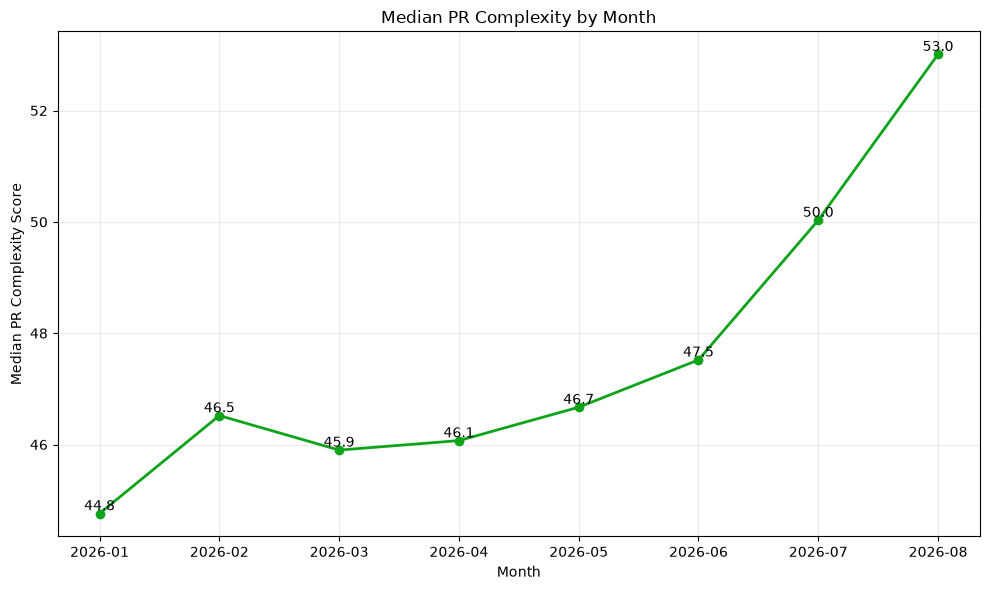

In [17]:
# ============================================================
# MEDIAN PR COMPLEXITY BY MONTH
# ============================================================

date_col = "merge_day"
complexity_col = "pr_complexity_score"   # change to "complexity_score" if needed

# Make sure date is datetime
df_title_body[date_col] = pd.to_datetime(
    df_title_body[date_col],
    errors="coerce"
)

# Create month
df_title_body["month"] = (
    df_title_body[date_col]
    .dt.to_period("M")
    .astype(str)
)

# Calculate median complexity by month
complexity_by_month = (
    df_title_body
    .groupby("month")[complexity_col]
    .median()
    .reset_index(name="median_complexity")
)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    complexity_by_month["month"],
    complexity_by_month["median_complexity"],
    marker="o",
    linewidth=2,
    color="#0ea31b"
)

ax.set_title("Median PR Complexity by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Median PR Complexity Score")
[ax.text(i, y, f"{y:.1f}", ha="center", va="bottom") for i, y in enumerate(complexity_by_month["median_complexity"])]

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

Number of PRS
Complexity
TTM
Which part of the formula added to the complexity score
Make methodlogy and steps

In [34]:
df.head(10)

,customer_id,user_id,repository_id,pull_request_id,oid,nwo,pr_number,title,body,combined_text_nlp,merge_day,merge_month,had_copilot_seat,files_added,files_deleted,files_modified,files_touched,lines_modified,code_lines_modified,config_lines_modified,lines_added_by_language,lines_deleted_by_language,languages_list,minutes_to_merge,num_reviewers,num_review_comments,is_code_pr,standardized_complexity_score,complexity_score,kw_feature,kw_bug_fix,kw_refactor,kw_documentation,kw_testing,kw_dependency,kw_security,kw_performance,kw_configuration,kw_release,kw_revert,keyword_categories,keyword_category_count,has_keyword_match,complexity_code_size,complexity_file_breadth,complexity_review_comments,complexity_reviewers,complexity_config,complexity_category_breadth,complexity_review_burden,pr_complexity_score,pr_complexity_level
0,11468,7204669,3,3769055762,1cab4250acd69a8a5435dff5bb7837f8b18d6e7c,github/github,434013,[ci-perf] Track A: cache tree_manifest and expected_blob_at in MergeQueues::RefContentsTest,"This PR was created by the [ci-perf automated software factory](https://github.com/github/github-automation/blob/main/.github/workflows/ci-perf.md?plain=1), which continuously discovers, scopes, and implements CI test-speed improvements in github/github based on Report Test Suite Stats evidence....","[ci-perf] Track A: cache tree_manifest and expected_blob_at in MergeQueues::RefContentsTest This PR was created by the [ci-perf automated software factory](https://github.com/github/github-automation/blob/main/.github/workflows/ci-perf.md?plain=1), which continuously discovers, scopes, and imple...",2026-06-08,2026-06-01,True,0,0,1,1,50,50,0,{'Ruby': 47},{'Ruby': 3},['Ruby'],14646,3,1,True,-42.42,43.00,True,True,False,True,True,True,False,True,False,False,True,"['feature', 'bug_fix', 'documentation', 'testing', 'dependency', 'performance', 'revert']",7,True,0.48,0.14,0.58,0.64,0.42,0.92,0.60,50.30,High
1,11468,25356636,3,3715497677,d4906653bc920bdea81be0ef2839810d81920da4,github/github,432817,Add customer_id to RepositoryUpdatePublisher,"- closes https://github.com/github/licensing/issues/4061\r\n\r\n<!--\r\nProvide context and explain why this pull request exists. Include screenshots, videos, and graphs here, if you have any.\r\n\r\nCode changes should be in response to an issue. If one does not already exist, create one in the...","Add customer_id to RepositoryUpdatePublisher - closes https://github.com/github/licensing/issues/4061\r\n\r\n<!--\r\nProvide context and explain why this pull request exists. Include screenshots, videos, and graphs here, if you have any.\r\n\r\nCode changes should be in response to an issue. If ...",2026-05-27,2026-05-01,True,0,0,5,5,128,128,0,{'Ruby': 126},{'Ruby': 2},['Ruby'],10375,3,4,True,-40.40,54.00,True,True,False,True,True,False,False,False,False,False,True,"['feature', 'bug_fix', 'documentation', 'testing', 'revert']",5,True,0.74,0.62,0.85,0.64,0.42,0.37,0.77,63.50,High
2,11468,1092941,3,3849514141,75efb97a61c627a22a5cefe096a71ed04954befe,github/github,435811,Improve ReindexUserRecordsJob UI rep,"Part of github/elasticsearch#9958\r\n\r\n<!--\r\nProvide context and explain why this pull request exists. Include screenshots, videos, and graphs here, if you have any.\r\n\r\nCode changes should be in response to an issue. If one does not already exist, create one in the relevant repository.\r...","Improve ReindexUserRecordsJob UI rep Part of github/elasticsearch#9958\r\n\r\n<!--\r\nProvide context and explain why this pull request exists. Include screenshots, videos, and graphs here, if you have any.\r\n\r\nCode changes should be in response to an issue. If one does not already exist, cre...",2026-06-11,2026-06-01,True,0,0,3,3,30,30,0,"{'HTML+ERB': 1, 'Ruby': 11}","{'HTML+ERB': 1, 'Ruby': 17}","['HTML+ERB', 'Ruby']",181,2,0,True,8.40,70.00,True,True,False,True,True,False,False,False,False,True,True,"['feature', 'bug_fix', 'documentation', 'testing', 'release', 'revert']",6,True,0.41,0.45,0.26,0.25,0.42,0.

## 11. Reload the dataset

Read the PR dataset with new complexity and old complexity scores.

In [ ]:
df = pd.read_csv("../data/prs_with_complexity.csv")

print(df.shape)
df.head(5)

(1606726, 56)


,customer_id,seat_count,available_customer_prs,repository_count,seat_group,pr_group,user_id,repository_id,pull_request_id,oid,title,body,combined_text_nlp,merge_day,merge_month,had_copilot_seat,files_added,files_deleted,files_modified,files_touched,lines_modified,code_lines_modified,config_lines_modified,lines_added_by_language,lines_deleted_by_language,languages_list,minutes_to_merge,num_reviewers,num_review_comments,is_code_pr,standardized_complexity_score,complexity_score,has_body,kw_feature,kw_bug_fix,kw_refactor,kw_documentation,kw_testing,kw_dependency,kw_security,kw_performance,kw_configuration,kw_release,kw_revert,keyword_categories,keyword_category_count,has_keyword_match,complexity_code_size,complexity_file_breadth,complexity_review_comments,complexity_reviewers,complexity_config,complexity_category_breadth,complexity_review_burden,pr_complexity_score,pr_complexity_level
0,11222,10484,140530,9427,4,5,99937741,1239475001,3779510455,d66433fe112ea9eb91db678c5c940c44e2c3c4ca,[Release] Develop to Master agent sse changes,## Purpose\r\nRelasing agent sse changes\r\n\r...,[Release] Develop to Master agent sse changes ...,2026-06-01,2026-06-01,True,7,0,27,34,2152,2134,18,"{'YAML': 17.0, 'XML': None, 'C#': None, 'TSX':...","{'YAML': None, 'XML': None, 'C#': None, 'TSX':...",['Markdown' 'TSX' 'TypeScript' 'YAML'],22,1,0,True,154.60,95.00,True,True,True,True,False,True,False,False,False,False,True,False,"['feature', 'bug_fix', 'refactor', 'testing', ...",5,True,0.96,0.93,0.36,0.42,0.67,0.86,0.38,77.17,Very High
1,11222,10484,140530,9427,4,5,267493148,1237611968,3702016153,3b9f626841c8840d59c095e8cf41f2e63800904a,Automating PR from script,Automating PR from script,Automating PR from script Automating PR from s...,2026-05-18,2026-05-01,False,1,0,6,7,857,788,69,"{'YAML': None, 'XML': None, 'C#': None, 'TSX':...","{'YAML': None, 'XML': None, 'C#': None, 'TSX':...",['JSON' 'OASv2-json'],0,0,0,True,24.61,82.00,True,False,False,False,False,False,False,False,False,False,False,False,[],0,False,0.91,0.71,0.36,0.12,0.79,0.09,0.26,61.52,High
2,11222,10484,140530,9427,4,5,192995331,1204482829,3609573181,65e71a42102caef1c52a57f3998cbc0487e0637d,fix: Update package-lock.json for developeruik...,<!-- Provide a general summary of your changes...,fix: Update package-lock.json for developeruik...,2026-04-30,2026-04-01,True,0,0,1,1,168,0,168,"{'YAML': None, 'XML': None, 'C#': None, 'TSX':...","{'YAML': None, 'XML': None, 'C#': None, 'TSX':...",['JSON'],16,1,0,False,-39.99,55.00,True,True,True,False,True,True,True,False,False,False,True,False,"['feature', 'bug_fix', 'documentation', 'testi...",6,True,0.18,0.15,0.36,0.42,0.86,0.91,0.38,36.63,Moderate
3,382,2036,4577,125,2,2,214534110,468367612,3726529045,841820a2f64d7ee86a4e786289c8ec80a246f448,Review: Bump versions for completion rename ch...,[ENG-19420],Review: Bump versions for completion rename ch...,2026-05-21,2026-05-01,True,0,0,2,2,6,2,4,"{'YAML': None, 'XML': 2.0, 'C#': None, 'TSX': ...","{'YAML': None, 'XML': 2.0, 'C#': None, 'TSX': ...",['Ruby' 'XML'],41,1,0,False,8.33,65.00,True,False,False,False,False,False,True,False,False,False,False,False,['dependency'],1,True,0.40,0.38,0.36,0.42,0.50,0.29,0.38,39.22,Moderate
4,382,2036,4577,125,2,2,214534110,468367612,3564103324,7bfbd161487c7284e7795f5e9d990342d25afca0,Review: Bump version for defaultBlcCode remova...,[ENG-17172],Review: Bump version for defaultBlcCode remova...,2026-04-21,2026-04-01,True,0,0,1,1,2,2,0,"{'YAML': None, 'XML': None, 'C#': None, 'TSX':...","{'YAML': None, 'XML': None, 'C#': None, 'TSX':...",['Ruby'],18,1,0,True,-43.02,2.00,True,False,False,False,False,False,True,False,False,False,False,False,['dependency'],1,True,0.40,0.15,0.36,0.42,0.18,0.29,0.38,31.32,Low


In [48]:

# ============================================================
# CASE STUDY: OLD VS NEW PR COMPLEXITY
# ============================================================

case_df = df.copy()

OLD_SCORE = "complexity_score"
NEW_SCORE = "pr_complexity_score"


# ------------------------------------------------------------
# Convert old and new scores to percentiles
# ------------------------------------------------------------

case_df["old_complexity_percentile"] = (
    case_df[OLD_SCORE].rank(pct=True) * 100
)

case_df["new_complexity_percentile"] = (
    case_df[NEW_SCORE].rank(pct=True) * 100
)

# Positive = new score considers PR more complex
# Negative = old score considers PR more complex
case_df["complexity_percentile_change"] = (
    case_df["new_complexity_percentile"]
    - case_df["old_complexity_percentile"]
)


# ============================================================
# SELECT CASES
# ============================================================

valid_cases = case_df.dropna(
    subset=[OLD_SCORE, NEW_SCORE]
)

cases = []


# ------------------------------------------------------------
# 1. NEW SCORE MUCH HIGHER THAN OLD
# ------------------------------------------------------------

new_higher = (
    valid_cases
    .nlargest(3, "complexity_percentile_change")
    .copy()
)

new_higher["case_type"] = "New score much higher"

cases.append(new_higher)


# ------------------------------------------------------------
# 2. OLD SCORE MUCH HIGHER THAN NEW
# ------------------------------------------------------------

old_higher = (
    valid_cases
    .nsmallest(3, "complexity_percentile_change")
    .copy()
)

old_higher["case_type"] = "Old score much higher"

cases.append(old_higher)


# ------------------------------------------------------------
# 3. BOTH SCORES HIGH
# ------------------------------------------------------------

high_candidates = valid_cases[
    (valid_cases["old_complexity_percentile"] >= 90)
    & (valid_cases["new_complexity_percentile"] >= 90)
]

both_high = (
    high_candidates
    .sample(
        n=min(3, len(high_candidates)),
        random_state=42
    )
    .copy()
)

both_high["case_type"] = "Both scores high"

cases.append(both_high)


# ------------------------------------------------------------
# 4. BOTH SCORES LOW
# ------------------------------------------------------------

low_candidates = valid_cases[
    (valid_cases["old_complexity_percentile"] <= 10)
    & (valid_cases["new_complexity_percentile"] <= 10)
]

both_low = (
    low_candidates
    .sample(
        n=min(3, len(low_candidates)),
        random_state=42
    )
    .copy()
)

both_low["case_type"] = "Both scores low"

cases.append(both_low)


# ============================================================
# COMBINE CASES
# ============================================================

case_studies = pd.concat(
    cases,
    ignore_index=True
)


# ============================================================
# PUT IMPORTANT COLUMNS FIRST
# ============================================================

important_columns = [
    "case_type",

    "pull_request_id",
    "customer_id",
    "repository_id",

    "title",
    "combined_text_nlp",

    OLD_SCORE,
    NEW_SCORE,

    "old_complexity_percentile",
    "new_complexity_percentile",
    "complexity_percentile_change",

    "pr_complexity_level",

    # Technical change
    "lines_modified",
    "code_lines_modified",
    "config_lines_modified",

    # File changes
    "files_added",
    "files_deleted",
    "files_modified",
    "files_touched",

    # Review burden
    "num_reviewers",
    "num_review_comments",

    # Categories
    "keyword_categories",
    "keyword_category_count",

    # Language / PR type
    "category",
    "repo_primary_language",

    # Copilot
    "had_copilot_seat",

    # Outcome
    "minutes_to_merge",
]

# Only keep columns that actually exist
important_columns = [
    col
    for col in important_columns
    if col in case_studies.columns
]

# Keep all remaining dataframe columns afterward
remaining_columns = [
    col
    for col in case_studies.columns
    if col not in important_columns
]

case_studies = case_studies[
    important_columns + remaining_columns
]


# ============================================================
# DISPLAY FULL CASE STUDIES
# ============================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 300)

print(f"Selected {len(case_studies)} PRs")

display(case_studies)


# ============================================================
# SMALL SUMMARY TABLE
# ============================================================

summary_columns = [
    col
    for col in [
        "case_type",
        "pull_request_id",
        "combined_text_nlp",

        OLD_SCORE,
        NEW_SCORE,

        "old_complexity_percentile",
        "new_complexity_percentile",
        "complexity_percentile_change",

        "code_lines_modified",
        "config_lines_modified",
        "files_touched",

        "num_reviewers",
        "num_review_comments",

        "keyword_categories",
        "keyword_category_count",

        "minutes_to_merge",
    ]
    if col in case_studies.columns
]

display(case_studies[summary_columns])

Selected 12 PRs


,case_type,pull_request_id,customer_id,repository_id,title,combined_text_nlp,complexity_score,pr_complexity_score,old_complexity_percentile,new_complexity_percentile,complexity_percentile_change,pr_complexity_level,lines_modified,code_lines_modified,config_lines_modified,files_added,files_deleted,files_modified,files_touched,num_reviewers,num_review_comments,keyword_categories,keyword_category_count,had_copilot_seat,minutes_to_merge,user_id,oid,nwo,pr_number,body,merge_day,merge_month,lines_added_by_language,lines_deleted_by_language,languages_list,is_code_pr,standardized_complexity_score,kw_feature,kw_bug_fix,kw_refactor,kw_documentation,kw_testing,kw_dependency,kw_security,kw_performance,kw_configuration,kw_release,kw_revert,has_keyword_match,complexity_code_size,complexity_file_breadth,complexity_review_comments,complexity_reviewers,complexity_config,complexity_category_breadth,complexity_review_burden
0,New score much higher,3727167709,11468,3,fix: migrate oauth user dependents to background delete,"fix: migrate oauth user dependents to background delete ### What approach did you choose and why?\n\nThis is the Authorization Platform OAuth slice of the Phase 2 user background-delete split, stacked on #432535.\n\n- Moves user-owned OAuth applications, OAuth authorizations, and OAuth accesses ...",57.00,81.95,57.20,96.60,39.40,Very High,158,158,0,0,0,12,12,7,33,"['feature', 'bug_fix', 'refactor', 'documentation', 'testing', 'dependency', 'security', 'release', 'revert']",9,True,29903,17889693,8fe326badba83a5b14b2d54a60f0dd2bbc1bebac,github/github,433198,"### What approach did you choose and why?\n\nThis is the Authorization Platform OAuth slice of the Phase 2 user background-delete split, stacked on #432535.\n\n- Moves user-owned OAuth applications, OAuth authorizations, and OAuth accesses from synchronous user `dependent: :destroy` cleanup to `...",2026-06-11,2026-06-01,{'Ruby': 132},{'Ruby': 26},['Ruby'],True,-38.80,True,True,True,True,True,True,True,False,False,True,True,True,0.72,0.84,1.00,0.99,0.39,1.00,0.99
1,New score much higher,3646022728,11468,3,Add `can_upgrade_plan` to `/copilot_internal/user` with SKU/predicate-based eligibility mapping,Add `can_upgrade_plan` to `/copilot_internal/user` with SKU/predicate-based eligibility mapping Closes https://github.com/github/copilot-api/issues/32867\r\n\r\n### What approach did you choose and why?\r\n\r\nAdded a new `can_upgrade_plan` boolean to `/copilot_internal/user` and centralized the...,57.00,78.61,57.20,93.60,36.40,Very High,199,199,0,0,0,7,7,4,18,"['feature', 'bug_fix', 'documentation', 'testing', 'dependency', 'security', 'configuration', 'release', 'revert']",9,True,5889,857688,1b04dfeec7385feaeea225637c0e687e44635386,github/github,431158,"Closes https://github.com/github/copilot-api/issues/32867\r\n\r\n### What approach did you choose and why?\r\n\r\nAdded a new `can_upgrade_plan` boolean to `/copilot_internal/user` and centralized the decision in a nil-safe helper (`can_upgrade_plan?(copilot_user, authorizer)`) to keep hot-path ...",2026-05-12,2026-05-01,{'Ruby': 199},{},['Ruby'],True,-38.82,True,True,False,True,True,True,True,False,True,True,True,True,0.78,0.71,0.97,0.78,0.39,1.00,0.89
2,New score much higher,3513919927,11468,3,Gate individual AI Usage page by CFI access,Gate individual AI Usage page by CFI access The individual AI Usage page (`/settings/billing/ai_usage`) was accessible to CB/CE users since access was only gated by feature flags. Users with Copilot Business or Enterprise seats should not see this page or its nav link; only CFI (Copilot for Indi...,49.00,62.20,37.70,74.00,36.30,High,66,66,0,0,0,4,4,4,7,"['feature', 'documentation', 'testing', 'security', 'configuration', 'release', 'revert']",7,True,204,1421848,b26329d58c8977911003d29a957ce35706750aa5,github/github,427140,The individual AI Usage page (`/settings/billing/ai_usage`) was accessible to CB/CE users since access was only gated by feature flags. Users with Copilot Business or Enterpris

,case_type,pull_request_id,combined_text_nlp,complexity_score,pr_complexity_score,old_complexity_percentile,new_complexity_percentile,complexity_percentile_change,code_lines_modified,config_lines_modified,files_touched,num_reviewers,num_review_comments,keyword_categories,keyword_category_count,minutes_to_merge
0,New score much higher,3727167709,"fix: migrate oauth user dependents to background delete ### What approach did you choose and why?\n\nThis is the Authorization Platform OAuth slice of the Phase 2 user background-delete split, stacked on #432535.\n\n- Moves user-owned OAuth applications, OAuth authorizations, and OAuth accesses ...",57.00,81.95,57.20,96.60,39.40,158,0,12,7,33,"['feature', 'bug_fix', 'refactor', 'documentation', 'testing', 'dependency', 'security', 'release', 'revert']",9,29903
1,New score much higher,3646022728,Add `can_upgrade_plan` to `/copilot_internal/user` with SKU/predicate-based eligibility mapping Closes https://github.com/github/copilot-api/issues/32867\r\n\r\n### What approach did you choose and why?\r\n\r\nAdded a new `can_upgrade_plan` boolean to `/copilot_internal/user` and centralized the...,57.00,78.61,57.20,93.60,36.40,199,0,7,4,18,"['feature', 'bug_fix', 'documentation', 'testing', 'dependency', 'security', 'configuration', 'release', 'revert']",9,5889
2,New score much higher,3513919927,Gate individual AI Usage page by CFI access The individual AI Usage page (`/settings/billing/ai_usage`) was accessible to CB/CE users since access was only gated by feature flags. Users with Copilot Business or Enterprise seats should not see this page or its nav link; only CFI (Copilot for Indi...,49.00,62.20,37.70,74.00,36.30,66,0,4,4,7,"['feature', 'documentation', 'testing', 'security', 'configuration', 'release', 'revert']",7,204
3,Old score much higher,3664749279,"Annotate 2 GraphQL types with docs_category for @github/customer-success-engineering-reviewers Hi @github/customer-success-engineering-reviewers, I'm Copilot, on behalf of @heiskr.\n\n## What\n\nThis PR annotates 2 GraphQL types (2 mutations) owned by your team with `docs_category :symbol`. The ...",67.00,27.00,70.90,9.20,-61.70,6,0,3,2,0,"['feature', 'bug_fix', 'documentation', 'performance', 'configuration']",5,11635
4,Old score much higher,3848572398,"Backport 434630 for 3.17: Disable Turbo for external SAML sign-in link - Backport of https://github.com/github/github/pull/434630\n\n### What approach did you choose and why?\n\nManual backport of the GHES external SAML sign-in link Turbo opt-out. This adds `data-turbo=""false""` to the existing e...",66.00,28.39,70.50,10.20,-60.30,11,0,2,2,0,"['feature', 'documentation', 'testing', 'dependency', 'security', 'revert']",6,1270
5,Old score much higher,3199624415,VM jobs deprecation: Migrate git_maintenance queue jobs from VM to Kubernetes workers ## Summary\n\nShared VM workers are deprecated at GitHub and we will not be maintaining them.\nThis PR migrates background job queues from dedicated VM worker pools (`lowworker`/`highworker`) to the **shared Ku...,65.00,30.28,70.20,14.80,-55.40,1,4,2,2,0,"['refactor', 'documentation', 'testing', 'performance', 'configuration', 'revert']",6,119227
6,Both scores high,3472497917,Dependency Graph: Update SBOM service with asynchronous access pattern See:\r\n- https://github.com/github/dependency-graph/issues/6413\r\n- https://github.com/github/dependency-graph/issues/10147\r\n- https://github.com/github/dependency-graph/issues/10169\r\n\r\n### What approach did you choos...,97.00,83.16,99.50,97.00,-2.50,2270,3,80,2,3,"['feature', 'bug_fix', 'documentation', 'testing', 'dependency', 'release', 'revert']",7,1378
7,Both scores high,3831736432,Expand MCP private server form with full ServerDetail schema fields Improves the MCP private server creation/edit form with full ServerDetail schema support.\n\nhttps://github.com/user-attachments/assets/da226048-dd04-4296-81cf-2c3e4fac9b67\n\n### What approach did you choose and why?\n\n- Expan...,82.00,77.57,90.20

In [20]:
github_prs = df_title_body[df_title_body["customer_id"] == 9919]
github_prs

print(f"Found {len(github_prs):,} PRs for customer_id 9919")

Found 0 PRs for customer_id 9919


## Interpretation

A useful way to describe the metric in the paper is:

> **PR complexity is operationalized as a composite measure of change size, file breadth, configuration impact, semantic breadth, and realized review burden. Each component is log-transformed and percentile-normalized before aggregation into a 0–100 score. Merge time is excluded from the score and used as an external outcome for validation.**

One limitation is that review comments and reviewer count occur after PR creation. Therefore, this score is best described as **realized PR complexity**, rather than a purely predictive pre-review complexity score.
